In [1]:
# Universidade Presbiteriana Mackenzie - Faculdade de Computação e Informática
# Disciplina: Inteligência Artificial - 7J SI - Prof. Dr. Leandro Zerbinatti
#
# Projeto: Análise de Padrões de Escolha e Desempenho de Heróis em Dota 2 por Faixa de Habilidade (MMR)
#
# Integrantes do grupo:
#   - David Haim Raiber | RA 10395618 | 10395618@mackenzista.com.br
#   - Isadora Caetano Brandão de Sousa    | RA 10420646 | 10420646@mackenzista.com.br
#   - Jennifer Aparecida de Sousa Tondade | RA 10420574 | 10420574@mackenzista.com.br
#   - Lucas Lacerda Gomes | RA 10322644 | 10322644@mackenzista.com.br
#
# Síntese do conteúdo deste arquivo:
#   Notebook de modelagem (N2): Começamos fazendo o teste da hipótese supervisionada de prever a
#   taxa de vitória a partir do atributo primário e dos papéis dos heróis, com
#   validação cruzada repetida e comparação com um baseline e depois fizemos a clusterização
#   (K-means e hierárquica) dos heróis em arquétipos de dependência de habilidade e depois
#   estabelecemos a relação dos arquétipos com a taxa de vitória e com atributo/papéis.
#
# Histórico de atualizações:
#
#   Data       | Autor                                  | Descrição
#   -----------|----------------------------------------|----------------------------------------
#   12/10/2026 | David, Isadora, Jennifer e Lucas       | Criação do notebook: Modelos supervisionados
#              |                                        | (baseline, regressão linear, Ridge e Random
#              |                                        | Forest), clusterização e análise dos arquétipos
#   15/10/2026 | David, Isadora, Jennifer e Lucas       | Inclusão da justificativa da mudança do objetivo
#              |                                        | principal e da apresentação do resultado negativo
#              |                                        | (diferença para o baseline e previsto x observado).

# Notebook 3: Modelagem e Resultados

Este notebook usa a base tratada no Notebook 2 (dota2_hero_preference_tratado.csv) e os dados brutos da coleta (dota2_herostats_opendota_live.csv). Ele segue duas etapas:

1. **Hipótese supervisionada (H1) - Objetivo principal inicial:** é possível prever a taxa de vitória de um herói a partir do atributo primário e dos papéis estratégicos? Os modelos são comparados a um baseline que sempre prevê a média, com validação cruzada repetida.
2. **Método alternativo - Clusterização:** como a etapa 1 não superou o baseline, os heróis são agrupados em arquétipos de comportamento (popularidade e variação de desempenho entre faixas de MMR) e a relação desses arquétipos com a taxa de vitória é avaliada.

**Por que o objetivo principal mudou?** O projeto começou com um problema supervisionado: um modelo que, dado o atributo e os papéis de um herói, previsse sua taxa de vitória. Antes de olhar os resultados, definiu-se o critério de decisão: um modelo só seria adotado se superasse, em validação cruzada repetida, o baseline que sempre prevê a média (R² maior e MAE menor). Nenhum dos três modelos (regressão linear, Ridge e Random Forest) atendeu ao critério, em nenhum dos quatro alvos testados (seção 1). Manter o objetivo original significaria apresentar como solução um modelo que prevê pior do que a média, o que não responde ao problema nem é defensável. Por isso, a pergunta foi reformulada: em vez de prever a taxa de vitória a partir de características fixas do herói, passou-se a descrever como o desempenho varia entre as faixas de MMR, por meio de arquétipos obtidos por clusterização, e a testar o que de fato se relaciona com a taxa de vitória. O resultado negativo é mantido e mostrado integralmente neste notebook.

A faixa Immortal continua excluída, pois o endpoint retornou 0 picks e 0 vitórias para todos os heróis.


In [2]:
import os, sys, subprocess, importlib, warnings

# Instala automaticamente os pacotes que faltarem, no mesmo Python do kernel
pacotes = {"numpy": "numpy", "pandas": "pandas", "matplotlib": "matplotlib",
"seaborn": "seaborn", "scipy": "scipy", "sklearn": "scikit-learn"}
faltando = [pip_nome for mod, pip_nome in pacotes.items() if importlib.util.find_spec(mod) is None]
if faltando:
    print("Instalando:", faltando)
    subprocess.check_call([sys.executable, "-m", "pip", "install", *faltando])
    importlib.invalidate_caches()

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from scipy.stats import spearmanr, kruskal, chi2_contingency
from sklearn.model_selection import RepeatedKFold, RepeatedStratifiedKFold, cross_val_score
from sklearn.dummy import DummyRegressor, DummyClassifier
from sklearn.linear_model import LinearRegression, Ridge
from sklearn.ensemble import RandomForestRegressor, RandomForestClassifier
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.cluster import KMeans, AgglomerativeClustering
from sklearn.metrics import silhouette_score, davies_bouldin_score, adjusted_rand_score

warnings.filterwarnings("ignore")
SEED = 42
os.makedirs("figuras", exist_ok=True)
sns.set_theme(style="whitegrid")
BRACKETS_VALIDAS = ["Herald", "Guardian", "Crusader", "Archon", "Legend", "Ancient", "Divine"]

tratado = pd.read_csv("dota2_hero_preference_tratado.csv")
bruto = pd.read_csv("dota2_herostats_opendota_live.csv")
ROLES = [c for c in tratado.columns if c.startswith("Role_")]
print(tratado.shape, bruto.shape)

(92, 14) (92, 28)


## 1. Hipótese supervisionada: prever a taxa de vitória a partir de atributo e papéis

- Variáveis de entrada: Atributo primário (one-hot) e papéis estratégicos (multi-hot);
- Alvos testados: Taxa de vitória média (principal), variação de desempenho, desvio-padrão da taxa de vitória e pick rate médio.

Como são apenas 92 heróis, a avaliação usa validação cruzada de 5 partições repetida 10 vezes e o R² é comparado ao do baseline.

In [3]:
X = pd.concat([pd.get_dummies(tratado["Primary Attribute"], prefix="Attr").astype(int), tratado[ROLES]], axis=1)
cv = RepeatedKFold(n_splits=5, n_repeats=10, random_state=SEED)
modelos = {
    "Baseline (média)": DummyRegressor(),
    "Regressão Linear": LinearRegression(),
    "Ridge": make_pipeline(StandardScaler(), Ridge(alpha=10)),
    "Random Forest": RandomForestRegressor(n_estimators=300, min_samples_leaf=3, random_state=SEED),
}
alvos = {"WinRate_Mean": "Taxa de vitória média", "WinRate_Delta": "Variação de desempenho (Divine - Herald)",
         "WinRate_Std": "Desvio-padrão da taxa de vitória", "PickRate_Mean": "Pick rate médio"}
linhas = []
for alvo, nome_alvo in alvos.items():
    for nome, modelo in modelos.items():
        r2 = cross_val_score(modelo, X, tratado[alvo], cv=cv, scoring="r2")
        mae = -cross_val_score(modelo, X, tratado[alvo], cv=cv, scoring="neg_mean_absolute_error")
        linhas.append({"Alvo": nome_alvo, "Modelo": nome, "R2 médio": r2.mean(), "R2 desvio": r2.std(), "MAE médio": mae.mean()})
res_sup = pd.DataFrame(linhas)
res_sup.round(3)

,Alvo,Modelo,R2 médio,R2 desvio,MAE médio
0,Taxa de vitória média,Baseline (média),-0.085,0.141,1.922
1,Taxa de vitória média,Regressão Linear,-0.325,0.296,2.121
2,Taxa de vitória média,Ridge,-0.252,0.243,2.062
3,Taxa de vitória média,Random Forest,-0.310,0.257,2.130
4,Variação de desempenho (Divine - Herald),Baseline (média),-0.063,0.100,2.382
5,Variação de desempenho (Divine - Herald),Regressão Linear,-0.298,0.302,2.662
6,Variação de desempenho (Divine - Herald),Ridge,-0.228,0.255,2.584
7,Variação de desempenho (Divine - Herald),Random Forest,-0.256,0.238,2.611
8,Desvio-padrão da taxa de vitória,Baseline (média),-0.065,0.090,0.498
9,Desvio-padrão da taxa de vitória,Regressão Linear,-0.246,0.337,0.525


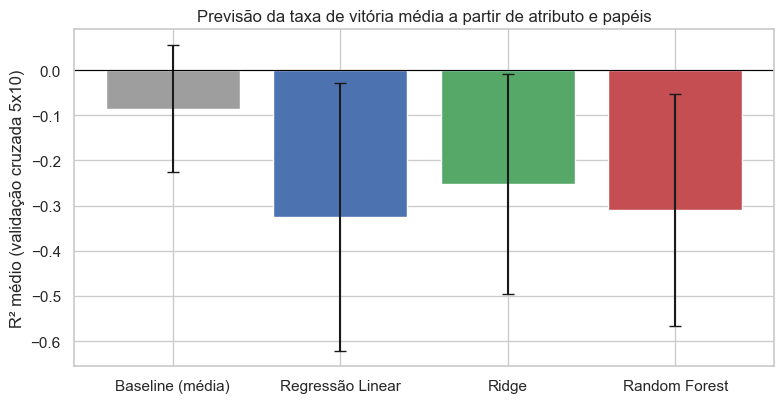

In [4]:
# R² em validação cruzada para prever a taxa de vitória média (R² < 0 = pior que prever a média)
sub = res_sup[res_sup["Alvo"] == "Taxa de vitória média"]
plt.figure(figsize=(8, 4.2))
cores = ["#9e9e9e", "#4c72b0", "#55a868", "#c44e52"]
plt.bar(sub["Modelo"], sub["R2 médio"], yerr=sub["R2 desvio"], color=cores, capsize=4)
plt.axhline(0, color="black", linewidth=0.8)
plt.ylabel("R² médio (validação cruzada 5x10)")
plt.title("Previsão da taxa de vitória média a partir de atributo e papéis")
plt.tight_layout()
plt.savefig("figuras/fig3_r2_modelos_supervisionados.png", dpi=200)
plt.show()

In [5]:
# Resultado negativo (1/2): diferença de cada modelo em relação ao baseline
base = res_sup[res_sup["Modelo"] == "Baseline (média)"].set_index("Alvo")
comp = res_sup[res_sup["Modelo"] != "Baseline (média)"].copy()
comp["Delta R2 vs baseline"] = comp["R2 médio"] - comp["Alvo"].map(base["R2 médio"])
comp["Delta MAE vs baseline"] = comp["MAE médio"] - comp["Alvo"].map(base["MAE médio"])
comp["Superou o baseline?"] = np.where((comp["Delta R2 vs baseline"] > 0) & (comp["Delta MAE vs baseline"] < 0), "Sim", "Não")
print("Modelos que superaram o baseline:", (comp["Superou o baseline?"] == "Sim").sum(), "de", len(comp))
comp[["Alvo", "Modelo", "R2 médio", "Delta R2 vs baseline", "MAE médio", "Delta MAE vs baseline", "Superou o baseline?"]].round(3)

Modelos que superaram o baseline: 0 de 12


,Alvo,Modelo,R2 médio,Delta R2 vs baseline,MAE médio,Delta MAE vs baseline,Superou o baseline?
1,Taxa de vitória média,Regressão Linear,-0.325,-0.240,2.121,0.199,Não
2,Taxa de vitória média,Ridge,-0.252,-0.167,2.062,0.140,Não
3,Taxa de vitória média,Random Forest,-0.310,-0.225,2.130,0.207,Não
5,Variação de desempenho (Divine - Herald),Regressão Linear,-0.298,-0.235,2.662,0.281,Não
6,Variação de desempenho (Divine - Herald),Ridge,-0.228,-0.165,2.584,0.202,Não
7,Variação de desempenho (Divine - Herald),Random Forest,-0.256,-0.194,2.611,0.230,Não
9,Desvio-padrão da taxa de vitória,Regressão Linear,-0.246,-0.181,0.525,0.027,Não
10,Desvio-padrão da taxa de vitória,Ridge,-0.165,-0.100,0.509,0.011,Não
11,Desvio-padrão da taxa de vitória,Random Forest,-0.221,-0.156,0.515,0.018,Não
13,Pick rate médio,Regressão Linear,-0.170,-0.058,0.627,0.000,Não


Ridge: desvio-padrão das previsões = 0.70 p.p. | desvio-padrão observado = 2.40 p.p. | correlação = -0.10
Random Forest: desvio-padrão das previsões = 0.64 p.p. | desvio-padrão observado = 2.40 p.p. | correlação = -0.22


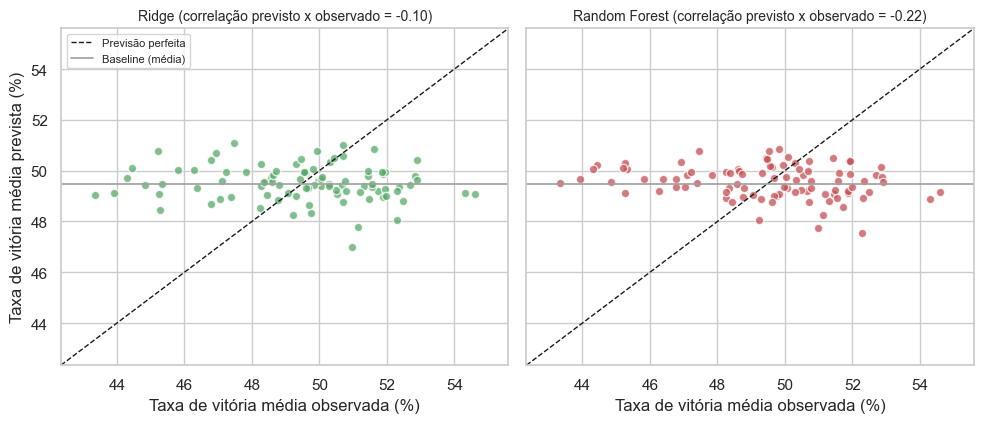

In [6]:
# Resultado negativo (2/2): previsto x observado (previsões fora da amostra, média das 10 repetições da validação cruzada)
from sklearn.base import clone
y = tratado["WinRate_Mean"].values
oof = {}
for nome in ["Ridge", "Random Forest"]:
    pred = np.zeros((10, len(y)))
    for k, (tr, te) in enumerate(cv.split(X)):
        m = clone(modelos[nome]).fit(X.iloc[tr], y[tr])
        pred[k // 5, te] = m.predict(X.iloc[te])
    oof[nome] = pred.mean(axis=0)

fig, axes = plt.subplots(1, 2, figsize=(10, 4.4), sharex=True, sharey=True)
lim = (y.min() - 1, y.max() + 1)
for ax, (nome, p), cor in zip(axes, oof.items(), ["#55a868", "#c44e52"]):
    r = np.corrcoef(y, p)[0, 1]
    ax.scatter(y, p, alpha=0.75, color=cor, edgecolor="white")
    ax.plot(lim, lim, "k--", linewidth=1, label="Previsão perfeita")
    ax.axhline(y.mean(), color="#9e9e9e", linewidth=1.2, label="Baseline (média)")
    ax.set_title(f"{nome} (correlação previsto x observado = {r:.2f})", fontsize=10)
    ax.set_xlabel("Taxa de vitória média observada (%)")
    ax.set_xlim(lim); ax.set_ylim(lim)
    print(f"{nome}: desvio-padrão das previsões = {p.std():.2f} p.p. | desvio-padrão observado = {y.std():.2f} p.p. | correlação = {r:.2f}")
axes[0].set_ylabel("Taxa de vitória média prevista (%)")
axes[0].legend(loc="upper left", fontsize=8)
plt.tight_layout()
plt.savefig("figuras/fig3b_previsto_vs_observado.png", dpi=200)
plt.show()

**Resultado negativo.** Nenhum modelo superou o baseline: todos os R² médios ficam abaixo do R² do baseline (que já é ligeiramente negativo) e o MAE também é pior na quase totalidade dos casos (a única exceção é o Ridge para o pick rate, com MAE menor em apenas 0,007 p.p., sem compensar o R² pior). Nenhum dos 12 modelos superou o baseline pelos dois critérios na tabela acima. O gráfico previsto x observado mostra a razão prática: as previsões ficam concentradas perto da média (desvio-padrão de cerca de 0,6 a 0,7 p.p., contra 2,4 p.p. observados) e a correlação entre previsto e observado é nula ou levemente negativa (-0,10 no Ridge e -0,22 no Random Forest), isto é, não há relação aproveitável entre o que o modelo prevê e o que ocorre com heróis que ficaram fora do treino (correlações levemente negativas são comuns em validação cruzada com poucos dados e sem sinal, porque deixar de fora um herói com taxa muito alta reduz a média do conjunto de treino). Atributo primário e papéis, sozinhos, não explicam a taxa de vitória dos heróis neste dataset, e a H1 foi rejeitada.

Possíveis explicações, que não foram testadas aqui: (i) são apenas 92 heróis para nove variáveis de entrada, então a validação cruzada tem pouco dado de treino e muita variância; (ii) a taxa de vitória de um herói tem pouca variação entre heróis (desvio-padrão de 2,4 p.p. em torno de 49,5%), de modo que há pouco sinal a ser explicado; (iii) fatores não presentes nos dados, como patch, composição das equipes e habilidade individual, devem pesar mais do que o atributo e os papéis.

Por isso, o método foi trocado, conforme o planejamento do projeto, e o resultado negativo permanece no relatório.

### 1.1 O que se relaciona com a taxa de vitória? (correlação de Spearman)

In [7]:
pr = pd.DataFrame({b: 100 * bruto[f"picks_{b}"] / bruto[f"picks_{b}"].sum() for b in BRACKETS_VALIDAS})
# Inclinação do pick rate: log(pick rate Divine / pick rate Herald). > 0: Herói mais escolhido em faixas altas
tratado["Pick_Slope"] = np.log(pr["Divine"] / pr["Herald"])

pares = [("PickRate_Mean", "WinRate_Mean"), ("WinRate_Delta", "WinRate_Mean"), ("WinRate_Std", "WinRate_Mean"),
         ("Pick_Slope", "WinRate_Delta"), ("PickRate_Mean", "WinRate_Delta")]
corr = []
for a, b in pares:
    rho, p = spearmanr(tratado[a], tratado[b])
    corr.append({"Variável A": a, "Variável B": b, "rho de Spearman": rho, "p-valor": p})
pd.DataFrame(corr).round(4)

,Variável A,Variável B,rho de Spearman,p-valor
0,PickRate_Mean,WinRate_Mean,0.3963,0.0001
1,WinRate_Delta,WinRate_Mean,-0.1339,0.2032
2,WinRate_Std,WinRate_Mean,0.0162,0.8783
3,Pick_Slope,WinRate_Delta,0.3881,0.0001
4,PickRate_Mean,WinRate_Delta,-0.4289,0.0000


## 2. Método alternativo: clusterização em arquétipos de dependência de habilidade

Variáveis de clusterização (padronizadas com StandardScaler): `WinRate_Delta`, `WinRate_Std`, `PickRate_Mean` e `Pick_Slope`, a taxa de vitória média não entra na clusterização, para que a relação entre arquétipos e taxa de vitória possa ser testada depois, sem circularidade. O número de grupos é escolhido entre 2 e 7 por índice de silhueta (maior é melhor) e Davies-Bouldin (menor é melhor), priorizando de 3 a 5 grupos, como previsto na metodologia.

In [8]:
FEATS = ["WinRate_Delta", "WinRate_Std", "PickRate_Mean", "Pick_Slope"]
Z = StandardScaler().fit_transform(tratado[FEATS])

sel = []
for k in range(2, 8):
    km = KMeans(k, n_init=20, random_state=SEED).fit(Z)
    ag = AgglomerativeClustering(k, linkage="ward").fit(Z)
    sel.append({"k": k,
                "Silhueta K-means": silhouette_score(Z, km.labels_), "Davies-Bouldin K-means": davies_bouldin_score(Z, km.labels_),
                "Silhueta hierárquica": silhouette_score(Z, ag.labels_), "Davies-Bouldin hierárquica": davies_bouldin_score(Z, ag.labels_)})
sel = pd.DataFrame(sel)
sel.round(3)

,k,Silhueta K-means,Davies-Bouldin K-means,Silhueta hierárquica,Davies-Bouldin hierárquica
0,2,0.340,1.118,0.325,1.045
1,3,0.294,1.244,0.267,1.311
2,4,0.333,1.005,0.292,1.101
3,5,0.331,0.969,0.316,0.981
4,6,0.304,1.050,0.312,0.978
5,7,0.337,0.897,0.309,0.908


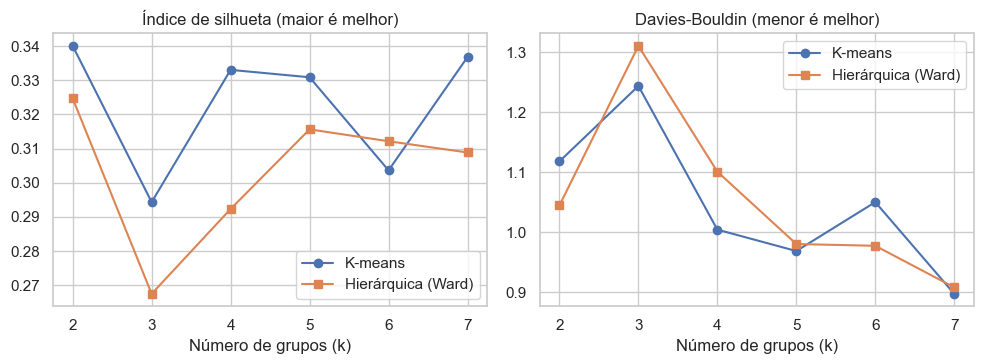

In [9]:
fig, ax = plt.subplots(1, 2, figsize=(10, 3.8))
ax[0].plot(sel["k"], sel["Silhueta K-means"], marker="o", label="K-means")
ax[0].plot(sel["k"], sel["Silhueta hierárquica"], marker="s", label="Hierárquica (Ward)")
ax[0].set_title("Índice de silhueta (maior é melhor)"); ax[0].set_xlabel("Número de grupos (k)"); ax[0].legend()
ax[1].plot(sel["k"], sel["Davies-Bouldin K-means"], marker="o", label="K-means")
ax[1].plot(sel["k"], sel["Davies-Bouldin hierárquica"], marker="s", label="Hierárquica (Ward)")
ax[1].set_title("Davies-Bouldin (menor é melhor)"); ax[1].set_xlabel("Número de grupos (k)"); ax[1].legend()
plt.tight_layout()
plt.savefig("figuras/fig_selecao_k.png", dpi=200)
plt.show()

In [10]:
K = 4
km = KMeans(K, n_init=20, random_state=SEED).fit(Z)
ag = AgglomerativeClustering(K, linkage="ward").fit(Z)
tratado["Cluster"] = km.labels_
print("Concordância K-means x hierárquica (Adjusted Rand Index):", round(adjusted_rand_score(km.labels_, ag.labels_), 3))
print("Silhueta K-means:", round(silhouette_score(Z, km.labels_), 3), "| Davies-Bouldin:", round(davies_bouldin_score(Z, km.labels_), 3))

perfil = tratado.groupby("Cluster").agg(Herois=("Name", "count"), WinRate_Mean=("WinRate_Mean", "mean"), WinRate_Delta=("WinRate_Delta", "mean"),
                                       WinRate_Std=("WinRate_Std", "mean"), PickRate_Mean=("PickRate_Mean", "mean"), Pick_Slope=("Pick_Slope", "mean"))
perfil.round(3)

Concordância K-means x hierárquica (Adjusted Rand Index): 0.335
Silhueta K-means: 0.333 | Davies-Bouldin: 1.005


,Herois,WinRate_Mean,WinRate_Delta,WinRate_Std,PickRate_Mean,Pick_Slope
Cluster,,,,,,
0,17,50.183,-3.566,1.320,1.524,-0.338
1,21,49.187,4.611,1.774,0.551,0.392
2,34,48.609,0.361,0.674,0.625,-0.385
3,20,50.710,0.040,0.544,2.063,0.229


In [11]:
# Heróis de cada grupo
for c, g in tratado.groupby("Cluster"):
    print(f"Cluster {c} ({len(g)}):", ", ".join(g.sort_values("PickRate_Mean", ascending=False)["Name"]))
    print()

Cluster 0 (17): Sniper, Axe, Ogre Magi, Necrophos, Witch Doctor, Phantom Assassin, Crystal Maiden, Wraith King, Drow Ranger, Vengeful Spirit, Slark, Nature's Prophet, Silencer, Slardar, Jakiro, Warlock, Sand King

Cluster 1 (21): Bounty Hunter, Outworld Devourer, Disruptor, Night Stalker, Keeper of the Light, Treant Protector, Dark Seer, Doom, Tinker, Clockwerk, Enigma, Pugna, Bane, Puck, Omniknight, Shadow Demon, Leshrac, Visage, Brewmaster, Lycan, Chen

Cluster 2 (34): Anti-Mage, Faceless Void, Sven, Viper, Tidehunter, Venomancer, Razor, Dragon Knight, Ancient Apparition, Storm Spirit, Nyx Assassin, Weaver, Ursa, Riki, Clinkz, Templar Assassin, Chaos Knight, Tiny, Dazzle, Io, Huskar, Kunkka, Bloodseeker, Death Prophet, Morphling, Lone Druid, Alchemist, Enchantress, Gyrocopter, Beastmaster, Broodmother, Naga Siren, Meepo, Batrider

Cluster 3 (20): Pudge, Lion, Shadow Fiend, Lina, Rubick, Invoker, Lifestealer, Juggernaut, Windranger, Spirit Breaker, Shadow Shaman, Earthshaker, Undying,

In [12]:
# Nomes dos arquétipos, atribuídos por regra a partir do perfil médio de cada grupo, independe da numeração dos clusters
p = perfil.copy()
NOMES = {}
NOMES[p["WinRate_Delta"].idxmax()] = "Alto teto de habilidade"
NOMES[p["WinRate_Delta"].idxmin()] = "Fortes em faixas baixas"
restantes = [c for c in p.index if c not in NOMES]
NOMES[p.loc[restantes, "PickRate_Mean"].idxmax()] = "Consistentes e populares"
NOMES[p.loc[restantes, "PickRate_Mean"].idxmin()] = "Consistentes de nicho"
tratado["Arquétipo"] = tratado["Cluster"].map(NOMES)
resumo = tratado.groupby("Arquétipo").agg(Herois=("Name", "count"), WinRate_Mean=("WinRate_Mean", "mean"), WinRate_Delta=("WinRate_Delta", "mean"),
                                         WinRate_Std=("WinRate_Std", "mean"), PickRate_Mean=("PickRate_Mean", "mean"), Pick_Slope=("Pick_Slope", "mean"))
resumo.round(3)

,Herois,WinRate_Mean,WinRate_Delta,WinRate_Std,PickRate_Mean,Pick_Slope
Arquétipo,,,,,,
Alto teto de habilidade,21,49.187,4.611,1.774,0.551,0.392
Consistentes de nicho,34,48.609,0.361,0.674,0.625,-0.385
Consistentes e populares,20,50.710,0.040,0.544,2.063,0.229
Fortes em faixas baixas,17,50.183,-3.566,1.320,1.524,-0.338


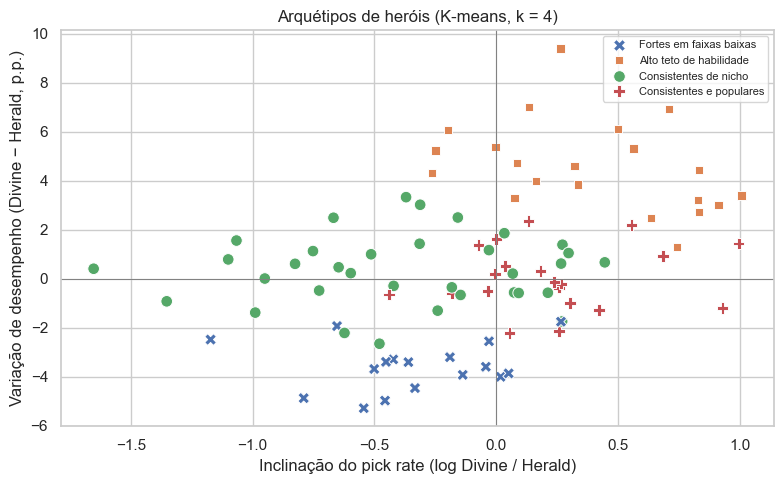

In [13]:
ordem = [NOMES[c] for c in sorted(NOMES)]
fig, ax = plt.subplots(figsize=(8, 5))
sns.scatterplot(data=tratado, x="Pick_Slope", y="WinRate_Delta", hue="Arquétipo", hue_order=ordem, style="Arquétipo", s=70, ax=ax)
ax.axhline(0, color="gray", linewidth=0.7); ax.axvline(0, color="gray", linewidth=0.7)
ax.set_xlabel("Inclinação do pick rate (log Divine / Herald)")
ax.set_ylabel("Variação de desempenho (Divine − Herald, p.p.)")
ax.set_title("Arquétipos de heróis (K-means, k = 4)")
ax.legend(fontsize=8, loc="best")
plt.tight_layout()
plt.savefig("figuras/fig4_arquetipos_dispersao.png", dpi=200)
plt.show()

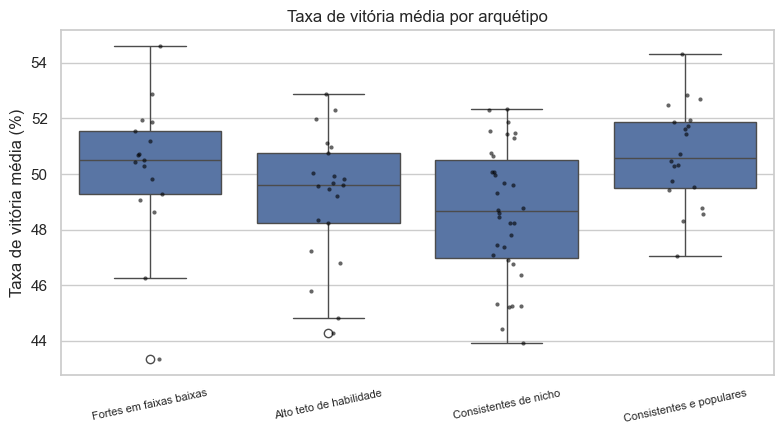

In [14]:
fig, ax = plt.subplots(figsize=(8, 4.5))
sns.boxplot(data=tratado, x="Arquétipo", y="WinRate_Mean", order=ordem, ax=ax)
sns.stripplot(data=tratado, x="Arquétipo", y="WinRate_Mean", order=ordem, color="black", size=3, alpha=0.6, ax=ax)
ax.set_xlabel(""); ax.set_ylabel("Taxa de vitória média (%)")
ax.set_title("Taxa de vitória média por arquétipo")
plt.xticks(rotation=12, fontsize=8)
plt.tight_layout()
plt.savefig("figuras/fig5_winrate_por_arquetipo.png", dpi=200)
plt.show()

### 2.1 Relação dos arquétipos com a taxa de vitória, o atributo primário e os papéis

In [15]:
grupos = [g["WinRate_Mean"].values for _, g in tratado.groupby("Cluster")]
h, p = kruskal(*grupos)
print(f"Kruskal-Wallis (WinRate_Mean entre arquétipos): H = {h:.3f}, p = {p:.4f}")
h2, p2 = kruskal(*[g["PickRate_Mean"].values for _, g in tratado.groupby("Cluster")])
print(f"Kruskal-Wallis (PickRate_Mean entre arquétipos): H = {h2:.3f}, p = {p2:.4f}")

ct = pd.crosstab(tratado["Arquétipo"], tratado["Primary Attribute"])
chi2, pchi, _, _ = chi2_contingency(ct)
print(f"Qui-quadrado (arquétipo x atributo primário): chi2 = {chi2:.2f}, p = {pchi:.4f}")
ct

Kruskal-Wallis (WinRate_Mean entre arquétipos): H = 11.344, p = 0.0100
Kruskal-Wallis (PickRate_Mean entre arquétipos): H = 59.695, p = 0.0000
Qui-quadrado (arquétipo x atributo primário): chi2 = 18.39, p = 0.0309


Primary Attribute,Agilidade,Forca,Inteligencia,Universal
Arquétipo,,,,
Alto teto de habilidade,1,6,10,4
Consistentes de nicho,16,8,3,7
Consistentes e populares,6,5,8,1
Fortes em faixas baixas,5,4,6,2


In [16]:
# Proporção de heróis com cada papel em cada arquétipo
tratado.groupby("Arquétipo")[ROLES].mean().round(2)

,Role_Carry,Role_Disabler,Role_Durable,Role_Escape,Role_Initiator,Role_Nuker,Role_Pusher,Role_Support
Arquétipo,,,,,,,,
Alto teto de habilidade,0.33,0.71,0.43,0.24,0.48,0.76,0.33,0.43
Consistentes de nicho,0.76,0.74,0.47,0.41,0.53,0.62,0.35,0.24
Consistentes e populares,0.65,0.60,0.25,0.45,0.25,0.80,0.25,0.45
Fortes em faixas baixas,0.59,0.82,0.29,0.35,0.47,0.65,0.18,0.53


### 2.2 Os arquétipos podem ser previstos a partir de atributo e papéis?

In [17]:
y = tratado["Cluster"]
cv_c = RepeatedStratifiedKFold(n_splits=4, n_repeats=10, random_state=SEED)
acc_base = cross_val_score(DummyClassifier(strategy="most_frequent"), X, y, cv=cv_c, scoring="accuracy")
acc_rf = cross_val_score(RandomForestClassifier(n_estimators=300, min_samples_leaf=2, random_state=SEED), X, y, cv=cv_c, scoring="accuracy")
print(f"Acurácia do baseline (classe majoritária): {acc_base.mean():.3f} ± {acc_base.std():.3f}")
print(f"Acurácia do Random Forest:                 {acc_rf.mean():.3f} ± {acc_rf.std():.3f}")

Acurácia do baseline (classe majoritária): 0.370 ± 0.022
Acurácia do Random Forest:                 0.359 ± 0.065


In [18]:
tratado.to_csv("dota2_hero_arquetipos.csv", index=False, encoding="utf-8")
print("Base com arquétipos salva: dota2_hero_arquetipos.csv")

Base com arquétipos salva: dota2_hero_arquetipos.csv
